# Length of stay: Majority class (baseline)

Always predicts the most common training bin (`<1 week`). Every real model must beat this (README: baselines first). The bins shift toward longer stays in later years, so this baseline does worse on val than its training share suggests.

**Task:** predict an animal's length-of-stay bin at intake: `<1 week`, `1-4 weeks`, `1-3 months`, `3+ months`. The bins are ordinal.
**Data:** Austin dogs and cats, intake-time features only (`utils.FEATURES`). Train is intakes before 2022 and val is 2022, grouped by animal (see `eda/austindataprocessing.ipynb`).
**Metrics:** accuracy, macro-F1, per-class precision/recall, and quadratic weighted kappa (QWK; rewards predictions that land close to the true bin).
**This notebook uses default hyperparameters** (no tuning). The only exceptions are settings that don't change the model itself: `random_state=utils.SEED`, `n_jobs=-1`, and an iteration cap where the default fails to converge. Tuning comes later.

In [ ]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

sys.path.append(str(Path.cwd().parent))  # repo root -> import utils
import utils

RESULTS_DIR = Path("results")
train, val, test = utils.load_los_splits()   # test is held out; models are compared on val
print(f"train {len(train):,}  val {len(val):,}  (test {len(test):,} untouched)")
#los is length of stay in days, los_bin is the length of stay binned into 0-3, 3-7, 7-30, 30-90, 90+ days
train["los_bin"].value_counts(normalize=True).reindex(utils.LOS_BIN_LABELS).round(3)

time_group_split: dropped 1,282 rows (0.8%) belonging to animals first seen in an earlier split
train 126,758  val 10,544  (test 21,835 untouched)


los_bin
<1 week       0.559
1-4 weeks     0.262
1-3 months    0.139
3+ months     0.040
Name: proportion, dtype: float64

In [2]:
from sklearn.dummy import DummyClassifier

model = DummyClassifier(strategy='most_frequent')
model

,strategy,'most_frequent'
,random_state,None
,constant,None


== Majority class (baseline) ==  macro-F1 0.151  accuracy 0.432
              precision    recall  f1-score   support

     <1 week       0.43      1.00      0.60      4554
   1-4 weeks       0.00      0.00      0.00      3420
  1-3 months       0.00      0.00      0.00      2017
   3+ months       0.00      0.00      0.00       553

    accuracy                           0.43     10544
   macro avg       0.11      0.25      0.15     10544
weighted avg       0.19      0.43      0.26     10544

quadratic weighted kappa: 0.000
train accuracy 0.559  |  fit 0.4s  predict 0.0s


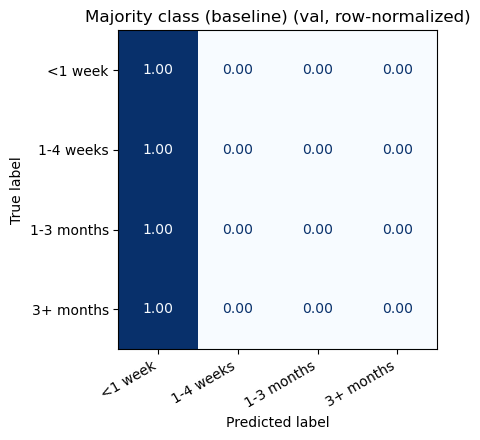

In [3]:
pipe, metrics = utils.evaluate_classifier(model, train, val, name="Majority class (baseline)",
                                           results_dir=RESULTS_DIR)